In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
np.random.seed(0)
torch.manual_seed(0)
random.seed(0)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [5]:
work_folder = 'edge_spen'
saving_folder = 'l0'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
n = 300

In [8]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)
print(s0)

2.1484375


In [9]:
vision=state_dim[-1]
from ppo_ants import *

In [10]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [11]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

In [12]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [13]:
def load_policy_weights(ppo_ants, actor_test, critic_test):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [14]:
import torch.distributions as distributions
def test_forward_pass(self, max_prob=False, save_pos = False, reset=True, bootstrapping=False, memory=False):

    saved_pattern = np.zeros_like(self.env.pheromones, dtype=bool)
    states, actions, rewards, done, episode_reward = [], [], [], False, 0.0
    if reset:
        self.env.reset_objects()
    self.env.transient()
    self.actor.eval()
    self.critic.eval()
    
    state = self.get_state().copy()
    state_tensor = torch.FloatTensor(state)

    if save_pos:
        pos = []
        pher = []

    while not done:

        if bootstrapping:
            if self.env.t >= 300 and self.env.t < 330:
                self.env.pheromones += np.eye(self.env.Lx)*s0

            # count the number of ants in the diagonal and off-diagonal positions (x=y in self.env.positions)
            diagonal_count = np.sum(self.env.positions[:, 0] == self.env.positions[:, 1])
            print(f"Current time step: {self.env.t}", f"Diagonal count: {diagonal_count}", end='\r')
                
        # Get action probabilities and value prediction from the agent.
        action_pred = self.actor(state_tensor)
        action_prob = F.softmax(action_pred, dim=-1)
        dist = distributions.Categorical(action_prob)
        action = dist.sample()

        if memory:
            if self.env.t >= 500 and self.env.t < 600:

                if self.env.t == 500:
                    saved_pattern = self.env.pheromones.copy() > 2*s0

                # random action between 0 and 7
                action = torch.randint(0, 8, (self.env.n_special,))
                # count the number of ants in the saved pattern positions
            
                ants_in_saved_pattern = np.sum(saved_pattern[self.env.positions[:, 0], self.env.positions[:, 1]])
                print(f"Current time step: {self.env.t}", f"Ants in saved pattern: {ants_in_saved_pattern}", end='\r')
        
        if max_prob:
            action = np.argmax(action_prob.detach(), axis=1)

        # Store log probability of the selected action.
        new_state, reward, done = self.execute_action(action.detach().numpy())
        
        rewards.append(reward)
        episode_reward += np.mean(reward)
        actions.append(action)
        if save_pos:
            pos.append(self.env.positions.copy())
            pher.append(self.env.pheromones.copy())

        state = new_state.copy() 
        state_tensor = torch.FloatTensor(state)
        states.append(state_tensor)


    # Convert to tensors and calculate advantages (returns - values).
    states = torch.cat(states)

    if save_pos: 
        return episode_reward, states, torch.cat(actions), rewards, pos, pher, saved_pattern

    else:
        return episode_reward, states, torch.cat(actions), rewards

In [15]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

ppo_ants.setup_networks()

load_policy_weights(ppo_ants, actor_test, critic_test)

b = 3.5
d = 0.4

ppo_ants.env.reset_objects()
ppo_ants.env.delta[:] = np.ones(n+n_special) * d
ppo_ants.env.beta[:] = np.ones(n+n_special) * b

episode_reward, states, actions, rewards, pos, pher, pattern = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                        reset=False, bootstrapping=True, memory=False)

KeyboardInterrupt: 

In [36]:
final_positions = ppo_ants.env.positions.copy()
final_field = ppo_ants.env.pheromones.copy()

In [37]:
print(np.sum(final_field),np.trace(final_field))

2183.5441839039177 2156.4762144412134


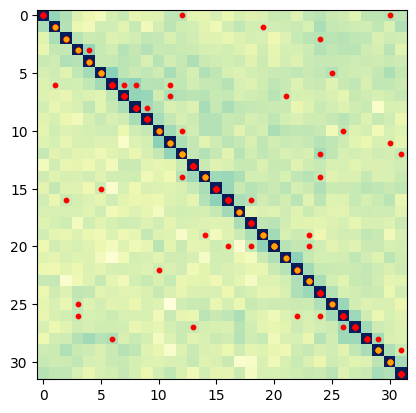

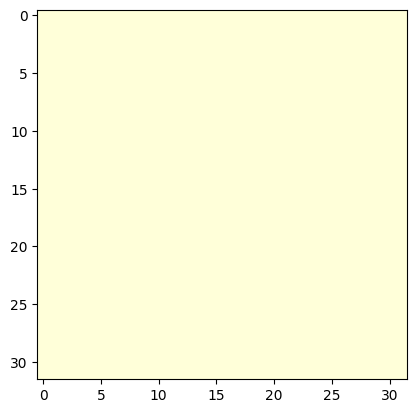

In [38]:
plt.imshow(np.log10(final_field+10e-4), cmap='YlGnBu')
plt.scatter(final_positions[:n, 1], final_positions[:n, 0], c='red', s=10, label='Ants')
plt.scatter(final_positions[n:, 1], final_positions[n:, 0], c='orange', s=10, label='Special Ants')
plt.show()
plt.imshow(pattern, cmap='YlGnBu')
plt.show()

# bootstrapping in beta-delta diagram

In [36]:
n_sim = 10
boot_value = np.zeros(n_sim*len(beta)*len(delta)).reshape(n_sim,len(beta), len(delta))
for sim in range(n_sim):
    for b in beta:
        for d in delta:
            print(f"Testing with delta = {d}, beta = {b}")    
            
            env, ppo_ants = setup_environment(
            n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision,
            gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
            clip_epsilon, entropy_coeff, policy_steps, learning_steps,
            state_dim, action_dim, clip_grad
            )

            ppo_ants.setup_networks()

            load_policy_weights(ppo_ants, actor_test, critic_test)

            ppo_ants.env.reset_objects()
            ppo_ants.env.delta[:] = np.ones(n+n_special) * d
            ppo_ants.env.beta[:] = np.ones(n+n_special) * b

            episode_reward, states, actions, rewards, pos, pher, pattern = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                                    reset=False, bootstrapping=True, memory=False)
            
            diagonal_count = np.sum(env.positions[:, 0] == env.positions[:, 1])
            boot_value[sim, beta.index(b), delta.index(d)] = diagonal_count

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5nt: 316
Testing with delta = 0.5, beta = 3.5nt: 283
Testing with delta = 0.6, beta = 3.5nt: 229
Testing with delta = 0.7, beta = 3.5nt: 205
Testing with delta = 0.8, beta = 3.5nt: 156
Testing with delta = 0.3, beta = 4.5nt: 135
Testing with delta = 0.4, beta = 4.5nt: 329
Testing with delta = 0.5, beta = 4.5nt: 327
Testing with delta = 0.6, beta = 4.5nt: 309
Testing with delta = 0.7, beta = 4.5nt: 294
Testing with delta = 0.8, beta = 4.5nt: 260
Testing with delta = 0.3, beta = 5.5nt: 216
Testing with delta = 0.4, beta = 5.5nt: 330
Testing with delta = 0.5, beta = 5.5nt: 329
Testing with delta = 0.6, beta = 5.5nt: 326
Testing with delta = 0.7, beta = 5.5nt: 322
Testing with delta = 0.8, beta = 5.5nt: 307
Testing with delta = 0.3, beta = 6.5nt: 292
Testing with delta = 0.4, beta = 6.5nt: 330
Testing with delta = 0.5, beta = 6.5nt: 330
Testing with delta = 0.6, beta = 6.5nt: 330
Testing with delta = 0.7, beta = 6.5nt:

In [37]:
boot_value

array([[[314., 281., 239., 205., 148., 137.],
        [329., 327., 307., 298., 259., 214.],
        [330., 330., 328., 323., 314., 292.],
        [330., 330., 328., 328., 323., 317.],
        [330., 330., 329., 330., 327., 326.],
        [330., 330., 330., 330., 330., 330.],
        [330., 330., 330.,  12., 330., 330.]],

       [[315., 288., 254., 203., 169., 125.],
        [329., 321., 305., 288., 259., 215.],
        [330., 329., 328., 321.,  88., 292.],
        [330., 330., 328., 327., 326., 322.],
        [330., 330., 330., 330., 329., 326.],
        [330., 330., 330., 330., 329., 330.],
        [330., 330., 330., 330., 330., 330.]],

       [[319., 290., 243., 191., 156., 121.],
        [329.,   9., 313., 294., 269., 223.],
        [330., 329., 325., 133., 310., 289.],
        [330., 330., 330., 326., 327., 157.],
        [330.,  15., 329., 330., 329., 327.],
        [330.,  11., 330., 330., 330., 328.],
        [330., 330., 330., 330.,  17., 330.]],

       [[313., 288., 245., 2

Text(0, 0.5, 'Beta')

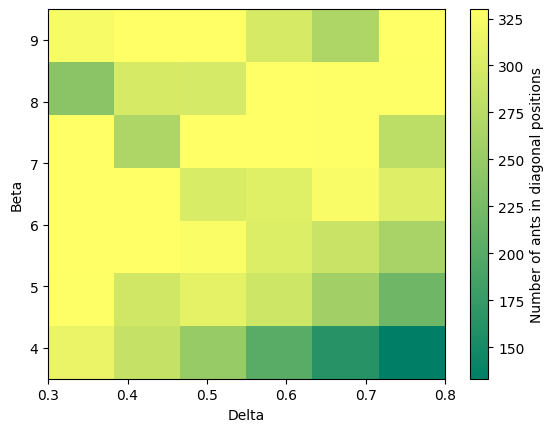

In [38]:
# plot the boot_value as a heatmap
avg_boot_value = boot_value.mean(axis=0)
plt.imshow(avg_boot_value, cmap='summer', extent=[min(delta), max(delta), min(beta), max(beta)], origin='lower', aspect='auto')
plt.colorbar(label='Number of ants in diagonal positions')
plt.xlabel('Delta')
plt.ylabel('Beta')  

# memory in beta-delta diagram

In [24]:
n_sim = 10
memo_value = np.zeros(n_sim*len(beta)*len(delta)).reshape(n_sim,len(beta), len(delta))
for sim in range(n_sim):
    for b in beta:
        for d in delta:
            print(f"Testing with delta = {d}, beta = {b}")    
            
            env, ppo_ants = setup_environment(
            n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision,
            gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
            clip_epsilon, entropy_coeff, policy_steps, learning_steps,
            state_dim, action_dim, clip_grad
            )

            ppo_ants.setup_networks()

            load_policy_weights(ppo_ants, actor_test, critic_test)

            ppo_ants.env.reset_objects()
            ppo_ants.env.delta[:] = np.ones(n+n_special) * d
            ppo_ants.env.beta[:] = np.ones(n+n_special) * b

            episode_reward, states, actions, rewards, pos, pher, pattern = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                                    reset=False, bootstrapping=False, memory=True)
            
            ants_in_saved_pattern = np.sum(pattern[env.positions[:, 0], env.positions[:, 1]])
            memo_value[sim, beta.index(b), delta.index(d)] = ants_in_saved_pattern

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5 pattern: 874
Testing with delta = 0.5, beta = 3.5 pattern: 579
Testing with delta = 0.6, beta = 3.5 pattern: 822
Testing with delta = 0.7, beta = 3.5 pattern: 422
Testing with delta = 0.8, beta = 3.5 pattern: 466
Testing with delta = 0.3, beta = 4.5 pattern: 483
Testing with delta = 0.4, beta = 4.5 pattern: 114
Testing with delta = 0.5, beta = 4.5 pattern: 801
Testing with delta = 0.6, beta = 4.5 pattern: 621
Testing with delta = 0.7, beta = 4.5 pattern: 520
Testing with delta = 0.8, beta = 4.5 pattern: 305
Testing with delta = 0.3, beta = 5.5 pattern: 34
Testing with delta = 0.4, beta = 5.5 pattern: 131
Testing with delta = 0.5, beta = 5.5 pattern: 976
Testing with delta = 0.6, beta = 5.5 pattern: 981
Testing with delta = 0.7, beta = 5.5 pattern: 424
Testing with delta = 0.8, beta = 5.5 pattern: 340
Testing with delta = 0.3, beta = 6.5 pattern: 341
Testing with delta = 0.4, beta = 6.5 pattern: 150
Testing with d

Text(0, 0.5, 'Beta')

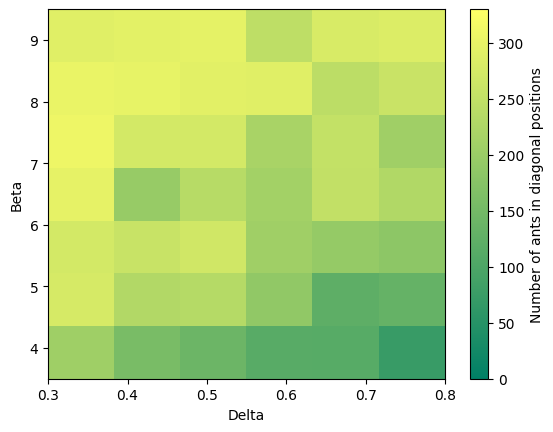

In [42]:
avg_memo_value = memo_value.mean(axis=0)
plt.imshow(
    avg_memo_value,
    cmap='summer',
    extent=[min(delta), max(delta), min(beta), max(beta)],
    origin='lower',
    aspect='auto',
    vmin=0,
    vmax=n + n_special,
)
plt.colorbar(label='Number of ants in diagonal positions')
plt.xlabel('Delta')
plt.ylabel('Beta')

In [39]:
# save the memo_value and boot_value arrays to a .npz file
np.savez('memo_boot_values.npz', memo_value=memo_value, boot_value=boot_value)

In [40]:
# read the memo_value and boot_value arrays from the .npz file
data = np.load('memo_boot_values.npz')
memo_value = data['memo_value']
boot_value = data['boot_value']

In [ ]:
# withdrawal 

# a t = T rimuovo gli smart/enhanced vedere dopo quanti time step gli abm si perdono, guardando le metriche
# come evolvono e quanto ( e se) decadono. 

# perturbation 

# a t = T metto a 0 celle nella grid distruggendo i trail.
# levare un numero di celle random ad ogni time step e vedere come evolvono le metriche
# levare una intera regione 